In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tunguz/online-retail/Online_Retail.csv


In [2]:
file_path = '/kaggle/input/datasets/tunguz/online-retail/Online_Retail.csv'
df = pd.read_csv(file_path, encoding = 'ISO-8859-1')
#df.shape
print(f"成功讀取！總共有{df.shape[0]}筆交易紀錄，{df.shape[1]}個欄位。")
df.head(5)

成功讀取！總共有541909筆交易紀錄，8個欄位。


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [4]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
df1 = df.dropna()
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    406829 non-null  object 
 1   StockCode    406829 non-null  object 
 2   Description  406829 non-null  object 
 3   Quantity     406829 non-null  int64  
 4   InvoiceDate  406829 non-null  object 
 5   UnitPrice    406829 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      406829 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 27.9+ MB


In [6]:
df1.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [7]:
df1 = df1[~df1["InvoiceNo"].astype(str).str.startswith("C")]

print("剩餘退貨筆數：", df1["InvoiceNo"].astype(str).str.startswith("C").sum())
print("剔除退貨後剩餘筆數：", df1.shape[0])

剩餘退貨筆數： 0
剔除退貨後剩餘筆數： 397924


In [8]:
df1 = df1[df1["Quantity"]>0]
df1 = df1[df1["UnitPrice"]>0]
print("剔除異常值後剩餘筆數：", df1.shape[0])

剔除異常值後剩餘筆數： 397884


In [9]:
df1["InvoiceDate"] = pd.to_datetime(df1["InvoiceDate"])
print(df1["InvoiceDate"].min())
print(df1["InvoiceDate"].max())

/tmp/ipykernel_15/1090450836.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df1["InvoiceDate"] = pd.to_datetime(df1["InvoiceDate"])


2010-12-01 08:26:00
2011-12-09 12:50:00


In [10]:
ref_date = df1["InvoiceDate"].max() + pd.Timedelta(days = 1)
print(f"分析基準日為：{ref_date}")

分析基準日為：2011-12-10 12:50:00


In [11]:
df1["TotalCost"] = df1["Quantity"]*df1["UnitPrice"]
df1.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalCost
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85


In [12]:
rfm = (
    df1.groupby("CustomerID")
    .agg({
    "InvoiceDate":lambda x:(ref_date - x.max()).days,
    "InvoiceNo":"nunique",
    "TotalCost":"sum"
    }).reset_index()
)
rfm.columns = ["CustomerID","Recency","Frequency","Monetary"]
rfm

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
...,...,...,...,...
4333,18280.0,278,1,180.60
4334,18281.0,181,1,80.82
4335,18282.0,8,2,178.05
4336,18283.0,4,16,2094.88


In [13]:
rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2054.266460
std,1721.808492,100.014169,7.697998,8989.230441
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,307.415000
50%,15299.500000,51.000000,2.000000,674.485000
75%,16778.750000,142.000000,5.000000,1661.740000
max,18287.000000,374.000000,209.000000,280206.020000


In [14]:
import matplotlib.pyplot as plt

(array([1890.,  807.,  363.,  237.,  225.,  190.,  190.,  168.,  141.,
         127.]),
 array([  1. ,  38.3,  75.6, 112.9, 150.2, 187.5, 224.8, 262.1, 299.4,
        336.7, 374. ]),
 <BarContainer object of 10 artists>)

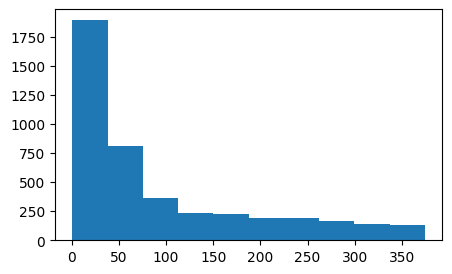

In [15]:
plt.figure(figsize=[5,3])
plt.hist(rfm["Recency"])

(array([4.254e+03, 6.200e+01, 1.400e+01, 1.000e+00, 4.000e+00, 1.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 2.000e+00]),
 array([  1. ,  21.8,  42.6,  63.4,  84.2, 105. , 125.8, 146.6, 167.4,
        188.2, 209. ]),
 <BarContainer object of 10 artists>)

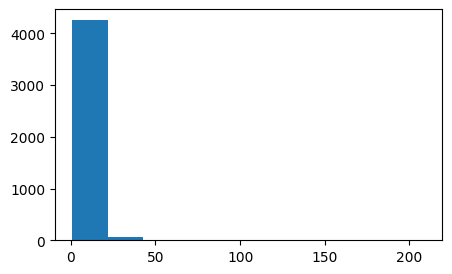

In [16]:
plt.figure(figsize=[5,3])
plt.hist(rfm["Frequency"])

(array([4.303e+03, 1.800e+01, 9.000e+00, 1.000e+00, 2.000e+00, 1.000e+00,
        2.000e+00, 0.000e+00, 0.000e+00, 2.000e+00]),
 array([3.75000000e+00, 2.80239770e+04, 5.60442040e+04, 8.40644310e+04,
        1.12084658e+05, 1.40104885e+05, 1.68125112e+05, 1.96145339e+05,
        2.24165566e+05, 2.52185793e+05, 2.80206020e+05]),
 <BarContainer object of 10 artists>)

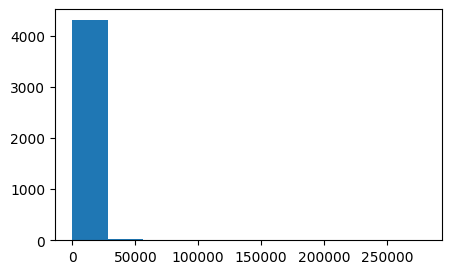

In [17]:
plt.figure(figsize=[5,3])
plt.hist(rfm["Monetary"])

In [18]:
from sklearn.preprocessing import StandardScaler

In [19]:
rfm_log = pd.DataFrame()

rfm_log["Recency_log"] = np.log(rfm["Recency"])
rfm_log["Frequency_log"] = np.log(rfm["Frequency"])
rfm_log["Monetary_log"] = np.log(rfm["Monetary"])

log 解決右偏問題，把資料壓縮拉平，然後標準化。

In [20]:
scaler = StandardScaler()
rfm_scaled_array = scaler.fit_transform(rfm_log)
rfm_scaled_array

array([[ 1.40989446, -1.04861045,  3.69871931],
       [-2.14649825,  1.11183567,  1.410201  ],
       [ 0.38397128,  0.49052242,  0.71641884],
       ...,
       [-1.17860486, -0.27904402, -1.11736527],
       [-1.66255156,  2.02965529,  0.83796882],
       [-0.00442205,  0.17112349,  0.73389579]])

In [21]:
rfm_scaled = pd.DataFrame(
    rfm_scaled_array,
    index = rfm.index,
    columns = ["Recency","Frequency","Monetary"]
)
rfm_scaled

,Recency,Frequency,Monetary
0,1.409894,-1.048610,3.698719
1,-2.146498,1.111836,1.410201
2,0.383971,0.490522,0.716419
3,-0.574674,-1.048610,0.698706
4,1.374758,-1.048610,-0.617446
...,...,...,...
4333,1.298690,-1.048610,-1.106086
4334,0.999081,-1.048610,-1.743850
4335,-1.178605,-0.279044,-1.117365
4336,-1.662552,2.029655,0.837969


In [22]:
rfm[["Recency","Frequency","Monetary"]].skew().round(2)

Recency       1.25
Frequency    12.07
Monetary     19.32
dtype: float64

In [23]:
rfm_log.skew().round(2)

Recency_log     -0.55
Frequency_log    0.78
Monetary_log     0.38
dtype: float64

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

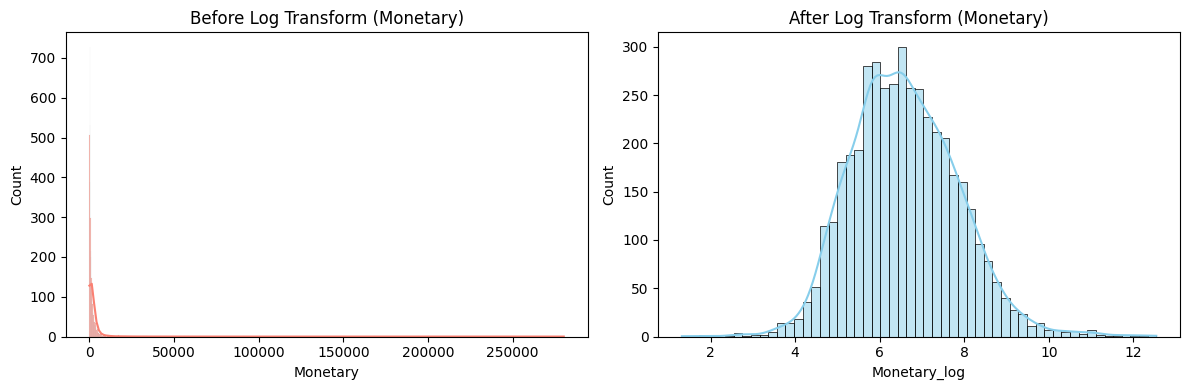

In [25]:
# 4. 視覺化對比：畫出 Monetary 轉換前後的分布直方圖（可存成圖片放進作品集）
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(rfm['Monetary'], kde=True, ax=axes[0], color='salmon')
axes[0].set_title('Before Log Transform (Monetary)')

sns.histplot(rfm_log['Monetary_log'], kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('After Log Transform (Monetary)')

plt.tight_layout()
plt.savefig('log_transform_comparison.png', dpi=300)
plt.show()

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

1. 手肘法（Elbow Method）— 看「群內緊密度」白話原理：手肘法計算的是 SSE（誤差平方和，又稱 Inertia），也就是「每個顧客距離自己所屬群組中心點的距離總和」。怎麼看圖：當群數 K 越大，每個群組分得越細，SSE 一定會越來越小。但分到某個臨界點後，再增加群數，SSE 下降的幅度會突然變得很平緩，整條折線看起來就像一隻彎曲的手臂。判斷標準：「手肘轉折處」 就是性價比最高的最佳 K 值（群數不會太多導致難以管理，誤差也已經降到足夠低）。
2. 輪廓係數（Silhouette Score）— 看「群與群之間分得有多開」白話原理：手肘法有時候轉折點不明顯（像一條平滑的曲線），這時就需要輪廓係數輔助。它同時衡量兩件事：「組內有多團結」（同群顧客有多像）以及 「組外有多疏遠」（跟隔壁群的顧客有多不一樣）。數值範圍與判斷標準：數值介於 -1 到 +1 之間。越接近 +1：代表分群效果極佳，同群很集中、不同群壁壘分明。接近 0：代表群組之間重疊嚴重、界線模糊。為負數：代表許多顧客被分錯群了。因此在圖表上，我們會挑選輪廓係數較高的峰值（並同時兼顧商業解釋性）作為最終 K 值。

In [27]:
k_range = range(2,11)
sse = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(rfm_scaled)
    sse.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, cluster_labels))

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)這行是在建立一個 K-means 分群器（設定好遊戲規則），括號裡的三個參數意義如下：n_clusters=k：告訴演算法「要把顧客分成幾群」（例如當 k=4 時，就是分成 4 群）。random_state=42：固定隨機種子。因為 K-means 一開始會「隨機」在空間中丟出 $K$ 個中心點來找鄰居，如果不固定這個數字，你每次按執行，分出來的群組順序或邊界可能會有些微不同；設成 42（業界慣用的固定數字，寫 0 或 123 也可以）能確保每次重跑程式都得到一模一樣的結果，方便寫報告與復現。n_init=10：重複嘗試 10 次並挑最好的結果。因為一開始的中心點是隨機放的，萬一運氣不好放到很偏僻的地方，分群效果就會很差。設定 10 代表讓電腦在背景重新隨機放 10 次起點、跑 10 遍分群，最後自動挑選「群內誤差（SSE）最小」的那一次當作最終模型，避免陷入局部最佳解。
cluster_labels = kmeans.fit_predict(rfm_scaled)這行是把你標準化後的顧客資料 rfm_scaled 餵給剛剛設定好的模型，它同時做了兩件事（fit + predict）：fit（學習／找中心點）：模型讀取 rfm_scaled 裡 4,000 多位顧客的 R、F、M 座標，反覆計算距離並移動群組中心，直到找到這 $K$ 個群組的最佳中心位置。predict（預測／貼標籤）：根據最終找到的中心位置，判斷每位顧客離哪一個中心點最近，並發給他一個群組編號（例如 0、1、2、3）。cluster_labels = ...：最後把這串貼好標籤的結果（一串長度與顧客人數相同的編號陣列），存進 cluster_labels 這個變數裡，方便下一步拿來計算輪廓係數（Silhouette Score）或貼回原始的 rfm 表格。

In [28]:
print(len(cluster_labels))
cluster_labels

4338


array([4, 1, 4, ..., 9, 1, 4], dtype=int32)

cluster_labels 是演算法在當下那一輪迴圈中，「逐一發給每位顧客的組別編號（貼紙）」，cluster_labels 在每一輪都會被新的結果覆蓋。
最後呈現的是 k=9 時，每位顧客的分群結果。

In [29]:
sse

[6396.774632987659,
 4846.050358331175,
 3957.182494869944,
 3390.0082561186355,
 2908.0271048000313,
 2612.0251113321533,
 2402.444567911376,
 2215.925452145464,
 2042.5977561753866]

記錄當分成 $K$ 群時，全體 4,338 位顧客距離各自中心點的誤差總和。所以 9 種 $K$ 值就會有 9 個總誤差數字，拿來畫左邊的手肘法折線圖。

In [30]:
silhouette_scores

[np.float64(0.43200903295690735),
 np.float64(0.33937281022633303),
 np.float64(0.3345277352853132),
 np.float64(0.3051169470545428),
 np.float64(0.3098282675526762),
 np.float64(0.30823620638340127),
 np.float64(0.2984081698914563),
 np.float64(0.28209982474598544),
 np.float64(0.2869350090904778)]

記錄當分成 $K$ 群時，「群內有多集中、群外分得多開」的整體平均分數（介於 -1 到 +1 之間）。同樣地，9 種 K 值只會算出 9 個總平均分數，拿來畫右邊的輪廓係數折線圖。

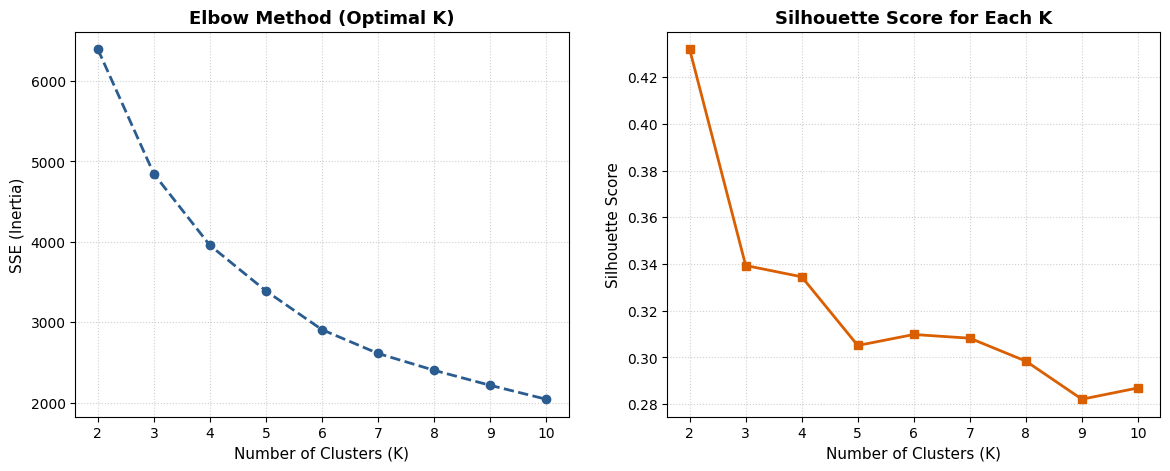

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左圖：手肘法 (Elbow Method)
axes[0].plot(k_range, sse, marker='o', linestyle='--', color='#2b5c8f', linewidth=2)
axes[0].set_title('Elbow Method (Optimal K)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[0].set_ylabel('SSE (Inertia)', fontsize=11)
axes[0].set_xticks(k_range)
axes[0].grid(True, linestyle=':', alpha=0.6)

# 右圖：輪廓係數 (Silhouette Score)
axes[1].plot(k_range, silhouette_scores, marker='s', linestyle='-', color='#d95f02', linewidth=2)
axes[1].set_title('Silhouette Score for Each K', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[1].set_ylabel('Silhouette Score', fontsize=11)
axes[1].set_xticks(k_range)
axes[1].grid(True, linestyle=':', alpha=0.6)

In [32]:
plt.tight_layout()
# 將圖表存成高解析度圖片，方便後續放進 GitHub README
fig.savefig('elbow_and_silhouette_v2.png', dpi=300, bbox_inches='tight')
plt.show()

# 印出具體數值方便對照
for k, s_score in zip(k_range, silhouette_scores):
    print(f"K = {k} | 輪廓係數 = {s_score:.4f}")

<Figure size 640x480 with 0 Axes>

K = 2 | 輪廓係數 = 0.4320
K = 3 | 輪廓係數 = 0.3394
K = 4 | 輪廓係數 = 0.3345
K = 5 | 輪廓係數 = 0.3051
K = 6 | 輪廓係數 = 0.3098
K = 7 | 輪廓係數 = 0.3082
K = 8 | 輪廓係數 = 0.2984
K = 9 | 輪廓係數 = 0.2821
K = 10 | 輪廓係數 = 0.2869


In [33]:
from scipy.stats import kruskal

In [34]:
#正式執行分群
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)

In [35]:
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)
rfm_scaled["Cluster"] = rfm["Cluster"]
rfm["Cluster"]

0       2
1       1
2       2
3       0
4       3
       ..
4333    3
4334    3
4335    0
4336    1
4337    2
Name: Cluster, Length: 4338, dtype: int32

貼完標籤後，換回原始的 rfm 做商業分析：分群號碼牌（Cluster 0, 1, 2, 3）貼回原始 rfm 表格後，你總不能跟老闆報告說：「這群 VIP 客戶的平均消費金額是 Log = 8.5」吧？老闆聽不懂，所以一定要換回原始的英鎊金額（例如「平均消費 £4,200」）來算營收佔比與擬定挽留預算！

In [36]:
cluster_summary = (
    rfm.groupby("Cluster").agg(
        客戶數=("CustomerID","count"),
        平均_Recency=('Recency', 'mean'),
        中位數_Recency=('Recency', 'median'),
        平均_Frequency=('Frequency', 'mean'),
        中位數_Frequency=('Frequency', 'median'),
        平均_Monetary=('Monetary', 'mean'),
        中位數_Monetary=('Monetary', 'median'),
        總營收貢獻=('Monetary', 'sum')
    ).round(2)
)

In [37]:
cluster_summary["人數占比%"] = cluster_summary["客戶數"]/(cluster_summary["客戶數"].sum())
cluster_summary["營收占比%"] = cluster_summary["總營收貢獻"]/(cluster_summary["總營收貢獻"].sum())

In [38]:
print("=== 各客群 RFM 與營收貢獻統計摘要 ===")
display(cluster_summary)

=== 各客群 RFM 與營收貢獻統計摘要 ===


,客戶數,平均_Recency,中位數_Recency,平均_Frequency,中位數_Frequency,平均_Monetary,中位數_Monetary,總營收貢獻,人數占比%,營收占比%
Cluster,,,,,,,,,,
0,760,18.72,18.0,2.00,2.0,503.88,429.36,382948.44,0.175196,0.042973
1,751,10.60,8.0,13.12,9.0,7739.90,3558.87,5812662.63,0.173121,0.652272
2,1255,72.79,57.0,4.12,4.0,1735.43,1276.00,2177961.28,0.289304,0.244401
3,1572,183.14,177.0,1.27,1.0,342.13,290.58,537835.55,0.362379,0.060354


為什麼用 Kruskal-Wallis 檢定？ 因為消費金額（Monetary）與頻率（Frequency）在原始數據上呈現右偏分布，使用無母數檢定（比較中位數與等級分布）比傳統 ANOVA 更嚴謹。

In [39]:
# 統計顯著性檢定：Kruskal-Wallis 檢定（計算各指標的 p-value）
print("\n=== Kruskal-Wallis 無母數統計檢定結果 ===")
for col in ['Recency', 'Frequency', 'Monetary']:
    # 依照 Cluster 0, 1, 2, 3 拆分成多組數據
    groups = [rfm[rfm['Cluster'] == c][col] for c in sorted(rfm['Cluster'].unique())]
    stat, p_val = kruskal(*groups)
    # 判斷是否顯著 (p < 0.05)
    sig_text = "極度顯著 (p < 0.001)" if p_val < 0.001 else ("顯著 (p < 0.05)" if p_val < 0.05 else "不顯著")
    print(f"{col:10s} | H統計量 = {stat:10.2f} | p-value = {p_val:.4e} -> {sig_text}")


=== Kruskal-Wallis 無母數統計檢定結果 ===
Recency    | H統計量 =    3087.41 | p-value = 0.0000e+00 -> 極度顯著 (p < 0.001)
Frequency  | H統計量 =    3281.43 | p-value = 0.0000e+00 -> 極度顯著 (p < 0.001)
Monetary   | H統計量 =    3087.36 | p-value = 0.0000e+00 -> 極度顯著 (p < 0.001)


證明這 4 群人在『多久沒買、買幾次、花多少錢』這三件事上，是真的有明顯差別，而不是運氣好隨便分出來的。

In [40]:
groups

[3       1757.55
 11      1168.06
 17      1313.10
 19       168.90
 24       742.93
          ...   
 4320     324.24
 4326     283.15
 4328     204.00
 4329     175.92
 4335     178.05
 Name: Monetary, Length: 760, dtype: float64,
 1       4310.00
 15      5226.23
 30      1845.31
 34      2780.66
 39      3018.63
          ...   
 4304     987.10
 4307    2073.09
 4309    2567.06
 4327    3078.58
 4336    2094.88
 Name: Monetary, Length: 751, dtype: float64,
 0       77183.60
 2        1797.24
 5        2506.04
 9        2811.43
 10       6207.67
           ...   
 4318     2338.60
 4319     2643.20
 4322     1213.16
 4323      801.51
 4337     1837.28
 Name: Monetary, Length: 1255, dtype: float64,
 4        334.40
 6         89.00
 7       1079.40
 8        459.40
 14       189.90
          ...   
 4330     335.86
 4331     110.38
 4332     173.90
 4333     180.60
 4334      80.82
 Name: Monetary, Length: 1572, dtype: float64]

col 依次為 R、F、M 之下，抓出 rfm 裡面 cluster 為 0、1、2、3 的顧客，讓 groups 變成一個裝著 4 疊數據的清單：[第0群的數據, 第1群的數據, 第2群的數據, 第3群的數據]，每次回圈被覆蓋，最後的是各分群每位顧客的 M 。

In [41]:
import seaborn as sns

In [42]:
# 1. 根據各群的實際平均 RFM 數值，自動對應商業標籤（避免 Cluster 編號隨機變動）
cluster_means = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

# 依照 Monetary 排序輔助判斷，或直接根據特性建立標籤字典
# 提示：執行後請核對下方印出的「標籤對照表」，確保名稱與數值完全吻合
label_map = {}
for c in cluster_means.index:
    r_val = cluster_means.loc[c, 'Recency']
    f_val = cluster_means.loc[c, 'Frequency']
    m_val = cluster_means.loc[c, 'Monetary']
    
    if r_val < cluster_means['Recency'].median() and m_val >= cluster_means['Monetary'].median():
        label_map[c] = 'Champions (Core Loyal)'        # 核心忠誠客
    elif r_val >= cluster_means['Recency'].median() and m_val >= cluster_means['Monetary'].median():
        label_map[c] = 'At-Risk High Value (Target)'   # 高價值流失預警客（重點挽留！）
    elif r_val < cluster_means['Recency'].median() and m_val < cluster_means['Monetary'].median():
        label_map[c] = 'Potential New Customers'       # 潛力新客
    else:
        label_map[c] = 'Hibernating / Lost'            # 一般流失客

print("=== 客群商業標籤對照表 ===")
for k, v in label_map.items():
    print(f"Cluster {k} -> {v}")

=== 客群商業標籤對照表 ===
Cluster 0 -> Potential New Customers
Cluster 1 -> Champions (Core Loyal)
Cluster 2 -> At-Risk High Value (Target)
Cluster 3 -> Hibernating / Lost


In [43]:
# 將商業標籤加入 rfm 與 rfm_scaled
rfm['Segment'] = rfm['Cluster'].map(label_map)
rfm_scaled['Segment'] = rfm['Segment']

In [44]:
display(rfm)

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,2,At-Risk High Value (Target)
1,12347.0,2,7,4310.00,1,Champions (Core Loyal)
2,12348.0,75,4,1797.24,2,At-Risk High Value (Target)
3,12349.0,19,1,1757.55,0,Potential New Customers
4,12350.0,310,1,334.40,3,Hibernating / Lost
...,...,...,...,...,...,...
4333,18280.0,278,1,180.60,3,Hibernating / Lost
4334,18281.0,181,1,80.82,3,Hibernating / Lost
4335,18282.0,8,2,178.05,0,Potential New Customers
4336,18283.0,4,16,2094.88,1,Champions (Core Loyal)


In [45]:
# 2. 將資料轉換為適合畫折線圖的長格式 (Melt)
rfm_melt = pd.melt(
    rfm_scaled.reset_index(),
    id_vars=['Segment'],
    value_vars=['Recency', 'Frequency', 'Monetary'],
    var_name='Metric',
    value_name='Standardized_Value'
)

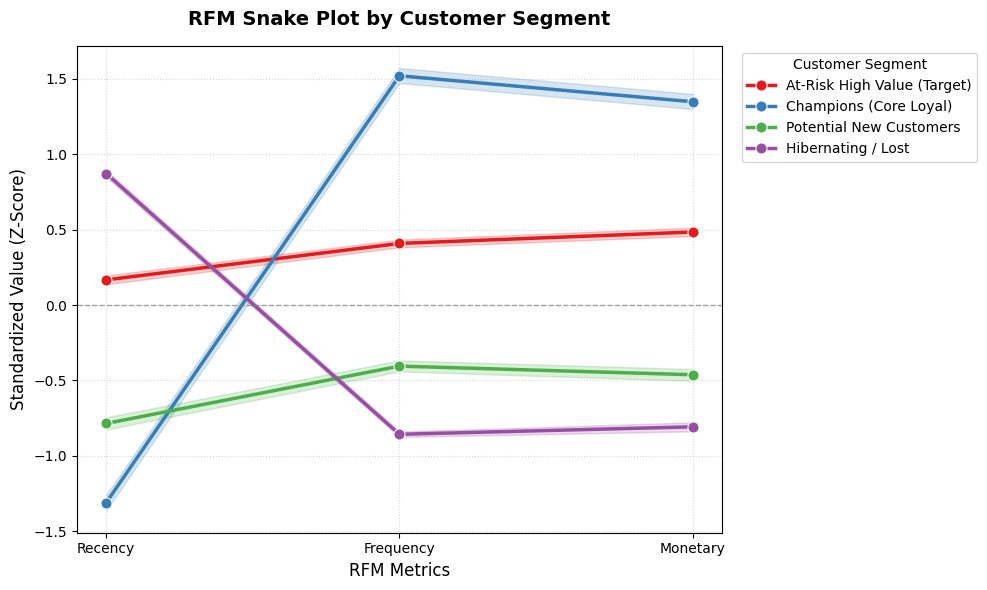

In [46]:
# 3. 繪製 Snake Plot 蛇形圖
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=rfm_melt,
    x='Metric',
    y='Standardized_Value',
    hue='Segment',
    marker='o',
    linewidth=2.5,
    markersize=8,
    palette='Set1'
)

# 加上平均值基準線 (y=0)
plt.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
plt.title('RFM Snake Plot by Customer Segment', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('RFM Metrics', fontsize=12)
plt.ylabel('Standardized Value (Z-Score)', fontsize=12)
plt.legend(title='Customer Segment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('rfm_snake_plot.png', dpi=300, bbox_inches='tight')
plt.show()

繪製「客群人數佔比 vs. 營收貢獻佔比圖」
圖表目的：使用原始真實金額（rfm），對比各個客群「佔全體會員多少比例」與「為公司貢獻了多少比例的營收」。

In [47]:
# 1. 彙整各商業客群的人數佔比與營收佔比
segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('CustomerID', 'count'),
    Total_Revenue=('Monetary', 'sum')
).reset_index()

In [48]:
segment_summary['Customer_Pct'] = (segment_summary['Customer_Count'] / segment_summary['Customer_Count'].sum() * 100).round(1)
segment_summary['Revenue_Pct'] = (segment_summary['Total_Revenue'] / segment_summary['Total_Revenue'].sum() * 100).round(1)

# 依照營收佔比由高到低排序，讓圖表更有重點
segment_summary = segment_summary.sort_values(by='Revenue_Pct', ascending=False)

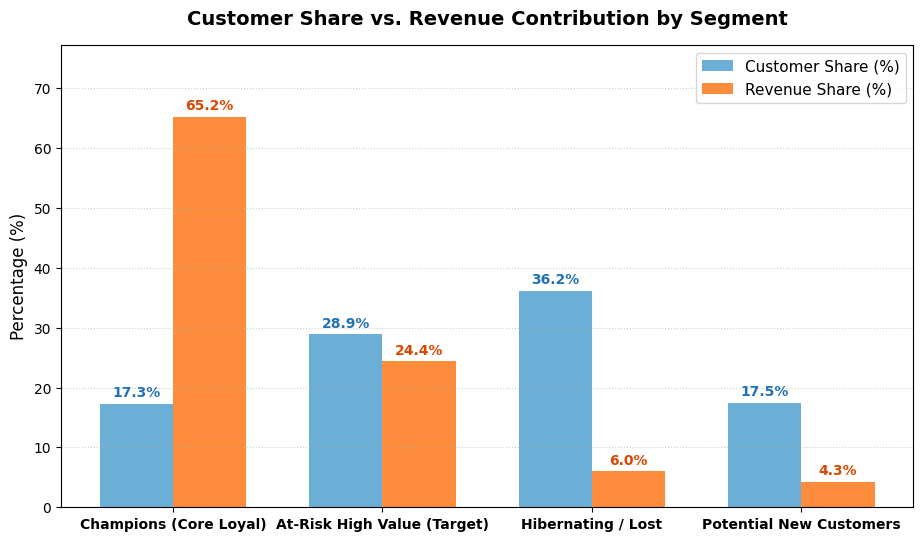

In [49]:
# 2. 繪製雙長條對比圖 (Grouped Bar Chart)
x = np.arange(len(segment_summary['Segment']))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
rects1 = ax.bar(x - width/2, segment_summary['Customer_Pct'], width, label='Customer Share (%)', color='#6baed6')
rects2 = ax.bar(x + width/2, segment_summary['Revenue_Pct'], width, label='Revenue Share (%)', color='#fd8d3c')

# 設定標題與座標軸
ax.set_title('Customer Share vs. Revenue Contribution by Segment', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(segment_summary['Segment'], fontsize=10, fontweight='bold')
ax.set_ylim(0, max(segment_summary['Revenue_Pct'].max(), segment_summary['Customer_Pct'].max()) + 12)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)

# 在每根長條上方標註精確百分比數字（面試官最看重的細節！）
for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'{height}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2171b5')

for rect in rects2:
    height = rect.get_height()
    ax.annotate(f'{height}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='#d94801')

In [50]:
plt.tight_layout()
fig.savefig('revenue_contribution_v2.png', dpi=300, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

In [51]:
display(segment_summary)

,Segment,Customer_Count,Total_Revenue,Customer_Pct,Revenue_Pct
1,Champions (Core Loyal),751,5812662.630,17.3,65.2
0,At-Risk High Value (Target),1255,2177961.283,28.9,24.4
2,Hibernating / Lost,1572,537835.551,36.2,6.0
3,Potential New Customers,760,382948.440,17.5,4.3
